<a href="https://colab.research.google.com/github/lin21022/Yuhsin-Lin/blob/main/module4_team2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import polars as pl
import numpy as np
from datetime import date
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import AdaBoostRegressor
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import RandomizedSearchCV

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers

%pip install lets-plot
from lets_plot import *
LetsPlot.setup_html()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 61.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [lets-plot]


In [2]:
!pip install scikeras
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV, KFold

In [3]:
bike_raw= pl.read_csv("https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes.csv")
bike_raw.head()

dteday,hr,casual,registered,temp_c,feels_like_c,hum,windspeed,weathersit,season,holiday,workingday
str,f64,i64,i64,f64,f64,f64,f64,i64,i64,i64,i64
"""1/1/2011""",0.0,3,13,3.0,3.0,0.7957,0.8,1,1,0,0
"""1/1/2011""",1.0,8,30,1.7,1.7,0.8272,0.8,1,1,0,0
"""1/1/2011""",2.0,5,26,1.9,1.9,0.8157,1.1,1,1,0,0
"""1/1/2011""",3.0,3,9,2.5,2.5,0.7831,0.8,1,1,0,0
"""1/1/2011""",4.0,0,1,2.0,2.0,0.8075,1.1,1,1,0,0


# Clean Data


In [4]:
def get_X(data):
    """
    Extract only input features.
    Works whether or not total_count exists.
    """
    if "total_count" not in data.columns:
        return data.drop(['dteday','date']).to_numpy()

    return data.drop(['total_count','dteday','date']).to_numpy()

def get_y(data):
    """
    Extract target if it exists.

    Returns None when total_count is not available,
    such as in the holdout prediction dataset.
    """

    if "total_count" not in data.columns:
        return None

    return data.select("total_count").to_numpy().ravel()

def create_target_bins(y):
    """Create discrete target bins for stratified sampling."""
    bins = np.percentile(y, np.linspace(0, 100, 11))
    bins = np.unique(bins)
    if len(bins) <= 2:
        return None
    return np.digitize(y, bins[1:-1])


In [5]:
def evaluate_model(model_name, y_test, predictions):
    """
    Evaluate predictions only when true target values exist.
    """

    if y_test is None:
        print(f"\n{model_name}")
        print("No total_count available. Predictions were generated.")
        return None

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print(f"\n{model_name}")
    print(f"MAE:  {mae:.2f} bikes")
    print(f"RMSE: {rmse:.2f} bikes")
    print(f"R²:   {r2:.3f}")

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [6]:
def holiday_expression(date_expr):
    """Identify major U.S. federal holidays."""
    month = date_expr.dt.month()
    day = date_expr.dt.day()
    weekday = date_expr.dt.weekday()

    new_years_day = (month == 1) & (day == 1)
    mlk_day = (month == 1) & (weekday == 1) & (day.is_between(15, 21))
    presidents_day = (month == 2) & (weekday == 1) & (day.is_between(15, 21))
    memorial_day = (month == 5) & (weekday == 1) & (day >= 25)
    juneteenth = (month == 6) & (day == 19)
    independence_day = (month == 7) & (day == 4)
    labor_day = (month == 9) & (weekday == 1) & (day.is_between(1, 7))
    veterans_day = (month == 11) & (day == 11)
    thanksgiving = (month == 11) & (weekday == 4) & (day.is_between(22, 28))
    christmas_day = (month == 12) & (day == 25)

    return (
        new_years_day
        | mlk_day
        | presidents_day
        | memorial_day
        | juneteenth
        | independence_day
        | labor_day
        | veterans_day
        | thanksgiving
        | christmas_day
    )


def holiday_feature_expressions(date_expr):
    """Create individual holiday indicator expressions."""
    month = date_expr.dt.month()
    day = date_expr.dt.day()
    weekday = date_expr.dt.weekday()

    return [
        ((month == 1) & (day == 1)).cast(pl.Int8).alias("new_years_day"),
        ((month == 1) & (weekday == 1) & day.is_between(15, 21)).cast(pl.Int8).alias("mlk_day"),
        ((month == 2) & (weekday == 1) & day.is_between(15, 21)).cast(pl.Int8).alias("presidents_day"),
        ((month == 5) & (weekday == 1) & (day >= 25)).cast(pl.Int8).alias("memorial_day"),
        ((month == 6) & (day == 19)).cast(pl.Int8).alias("juneteenth"),
        ((month == 7) & (day == 4)).cast(pl.Int8).alias("independence_day"),
        ((month == 9) & (weekday == 1) & day.is_between(1, 7)).cast(pl.Int8).alias("labor_day"),
        ((month == 11) & (day == 11)).cast(pl.Int8).alias("veterans_day"),
        ((month == 11) & (weekday == 4) & day.is_between(22, 28)).cast(pl.Int8).alias("thanksgiving"),
        ((month == 12) & (day == 25)).cast(pl.Int8).alias("christmas_day"),
    ]


# ---------------------------------------------------------
# Data Cleaning & Feature Engineering
# ---------------------------------------------------------

def cleanh(dataset_name, test=False):
    date_column = pl.col("date")
    holiday_today = holiday_expression(date_column)
    holiday_tomorrow = holiday_expression(date_column.dt.offset_by("1d"))
    holiday_yesterday = holiday_expression(date_column.dt.offset_by("-1d"))

    bike = (
        dataset_name
        .with_columns(
            pl.col("dteday")
            .str.strptime(pl.Date, format="%m/%d/%Y", strict=False)
            .alias("date")
        )
        .sort(["date", "hr"])
        .with_columns([
            pl.col("date").dt.year().alias("year"),
            pl.col("date").dt.month().alias("month"),
            pl.col("date").dt.day().alias("day_of_month"),
            pl.col("date").dt.ordinal_day().alias("day_of_year"),
            pl.col("date").dt.weekday().alias("day_of_week"),
            (pl.col("date").dt.weekday() >= 6).cast(pl.Int8).alias("is_weekend"),
            pl.col("hr").is_between(7, 9).cast(pl.Int8).alias("morning_rush"),
            pl.col("hr").is_between(16, 19).cast(pl.Int8).alias("evening_rush"),
            ((pl.col("hr") < 6) | (pl.col("hr") > 21)).cast(pl.Int8).alias("is_night"),
            pl.col("hr").is_between(8, 17).cast(pl.Int8).alias("business_hours"),
        ])
        .with_columns([
            # Cyclical time encodings
            (2 * np.pi * pl.col("hr") / 24).sin().alias("hour_sin"),
            (2 * np.pi * pl.col("hr") / 24).cos().alias("hour_cos"),
            (2 * np.pi * pl.col("day_of_week") / 7).sin().alias("weekday_sin"),
            (2 * np.pi * pl.col("day_of_week") / 7).cos().alias("weekday_cos"),
            (2 * np.pi * pl.col("month") / 12).sin().alias("month_sin"),
            (2 * np.pi * pl.col("month") / 12).cos().alias("month_cos"),
            (2 * np.pi * pl.col("day_of_year") / 365.25).sin().alias("year_sin"),
            (2 * np.pi * pl.col("day_of_year") / 365.25).cos().alias("year_cos"),
            # Holiday proximity indicators
            holiday_today.cast(pl.Int8).alias("is_holiday"),
            holiday_yesterday.cast(pl.Int8).alias("day_after_holiday"),
            holiday_tomorrow.cast(pl.Int8).alias("day_before_holiday"),
            (holiday_today & (pl.col("date").dt.weekday() >= 6)).cast(pl.Int8).alias("holiday_weekend"),
        ])
        .with_columns(holiday_feature_expressions(pl.col("date")))
        .sort(["date", "hr"])
        .drop_nulls()
    )

    if not test:
        bike = (
            bike
            .with_columns((pl.col("casual") + pl.col("registered")).alias("total_count"))
            .drop(["casual", "registered"])
        )

    return bike

In [7]:
def cleanh_byday(dataset_name, test=False):
  bike_h=cleanh(dataset_name)
  bike=bike_h.group_by(pl.col('date'))
  return bike


In [8]:
bike_h= cleanh(bike_raw)
# bike_h.describe()
bike_byday= cleanh_byday(bike_raw)
bike_byday

In [9]:
bike_h.describe()

statistic,dteday,hr,temp_c,feels_like_c,hum,windspeed,weathersit,season,holiday,workingday,date,year,month,day_of_month,day_of_year,day_of_week,is_weekend,morning_rush,evening_rush,is_night,business_hours,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos,year_sin,year_cos,is_holiday,day_after_holiday,day_before_holiday,holiday_weekend,new_years_day,mlk_day,presidents_day,memorial_day,juneteenth,independence_day,labor_day,veterans_day,thanksgiving,christmas_day,total_count
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""112475""",112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,"""112475""",112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",null,11.501098,15.376487,14.659325,0.636624,13.100614,1.405441,2.495799,0.0303,0.684312,"""2017-06-01 00:13:39.638141""",2016.921263,6.458689,15.729149,181.151705,3.999653,0.285815,0.125014,0.166686,0.333256,0.416715,-0.000058,-0.0001,0.000208,0.000316,-0.001809,-0.014241,0.006075,-0.010877,0.027099,0.027099,0.026886,0.004054,0.002774,0.002774,0.002774,0.002774,0.002774,0.002774,0.002774,0.002561,0.002561,0.002561,339.628237
"""std""",null,6.921864,9.749467,11.428324,0.190328,7.8576,0.68345,1.101152,0.171412,0.464791,null,3.702171,3.423022,8.800085,104.654533,2.000398,0.451804,0.330737,0.372697,0.471379,0.493017,0.70713,0.707089,0.707177,0.707043,0.709176,0.704892,0.708992,0.705112,0.162374,0.162374,0.161751,0.063544,0.052595,0.052595,0.052595,0.052595,0.052595,0.052595,0.052595,0.050537,0.050537,0.050537,342.495915
"""min""","""1/1/2011""",0.0,-14.7,-24.0,0.0889,0.0,1.0,1.0,0.0,0.0,"""2011-01-01""",2011.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,-1.0,-1.0,-0.974928,-0.900969,-1.0,-1.0,-0.999999,-0.999979,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",null,6.0,7.6,5.4,0.4841,7.7,1.0,2.0,0.0,0.0,"""2014-03-17""",2014.0,3.0,8.0,91.0,2.0,0.0,0.0,0.0,0.0,0.0,-0.707107,-0.707107,-0.781831,-0.900969,-0.866025,-0.866025,-0.703677,-0.71052,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,62.0
"""50%""",null,12.0,16.0,16.0,0.6409,12.2,1.0,2.0,0.0,1.0,"""2017-06-01""",2017.0,6.0,16.0,181.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.8370e-16,-2.4493e-16,-0.222521,1.2246e-16,-1.8370e-16,0.017202,-0.016127,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,237.0
"""75%""",null,18.0,23.5,23.5,0.7988,17.5,2.0,3.0,0.0,1.0,"""2020-08-16""",2020.0,9.0,23.0,271.0,6.0,1.0,0.0,0.0,1.0,1.0,0.707107,0.707107,0.781831,0.62349,0.5,0.5,0.711276,0.690574,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,507.0
"""max""","""9/9/2023""",23.0,40.5,49.6,1.0,69.8,4.0,4.0,1.0,1.0,"""2023-10-31""",2023.0,12.0,31.0,366.0,7.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.974928,1.0,1.0,1.0,0.999986,0.999991,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2262.0


# Neural Network

In [10]:
def get_top_features(
    model,
    X_val,
    y_val_log,
    feature_names,
    smearing_factor=1.0,
    n_repeats=10
):
    """
    Calculate permutation importance using validation MAE.
    """

    y_val_actual = np.expm1(y_val_log)

    # Baseline predictions
    baseline_predictions_log = (
        model
        .predict(X_val, verbose=0)
        .ravel()
    )

    baseline_predictions = (
        np.exp(baseline_predictions_log) *
        smearing_factor
    ) - 1

    baseline_predictions = np.maximum(
        baseline_predictions,
        0
    )

    baseline_mae = mean_absolute_error(
        y_val_actual,
        baseline_predictions
    )

    rng = np.random.default_rng(42)
    importance_results = []

    for feature_index, feature_name in enumerate(feature_names):

        shuffled_mae_values = []

        for _ in range(n_repeats):

            X_shuffled = X_val.copy()

            # Shuffle only one feature
            X_shuffled[:, feature_index] = rng.permutation(
                X_shuffled[:, feature_index]
            )

            shuffled_predictions_log = (
                model
                .predict(X_shuffled, verbose=0)
                .ravel()
            )

            shuffled_predictions = (
                np.exp(shuffled_predictions_log) *
                smearing_factor
            ) - 1

            shuffled_predictions = np.maximum(
                shuffled_predictions,
                0
            )

            shuffled_mae = mean_absolute_error(
                y_val_actual,
                shuffled_predictions
            )

            shuffled_mae_values.append(
                shuffled_mae
            )

        importance_results.append({
            "feature": feature_name,
            "importance": (
                np.mean(shuffled_mae_values) -
                baseline_mae
            ),
            "importance_std": np.std(
                shuffled_mae_values
            )
        })

    return (
        pl.DataFrame(importance_results)
        .sort("importance", descending=True)
        .head(10)
    )

In [11]:

def dense_hol(
    data,
    holdout=None,
    test_size=0.2,
    peak_weight=0.75,
    apply_smearing=True
):
    """Train and evaluate a dense neural network with holiday features."""
    np.random.seed(42)
    tf.random.set_seed(42)

    # 1. Dataset splitting
    if holdout is not None:
        X_train_full = get_X(data)
        y_train_full = get_y(data)
        X_test = get_X(holdout)
        y_test = get_y(holdout) if "total_count" in holdout.columns else None

        y_binned = create_target_bins(y_train_full)
        stratify_opt = y_binned if y_binned is not None else None

        X_train, X_val, y_train, y_val = train_test_split(
            X_train_full,
            y_train_full,
            test_size=0.20,
            random_state=42,
            stratify=stratify_opt
        )
    else:
        X = get_X(data)
        y = get_y(data)

        y_binned = create_target_bins(y)
        stratify_test = y_binned if y_binned is not None else None

        X_train_full, X_test, y_train_full, y_test = train_test_split(
            X,
            y,
            test_size=test_size,
            random_state=42,
            stratify=stratify_test
        )

        y_train_bins = create_target_bins(y_train_full)
        stratify_val = y_train_bins if y_train_bins is not None else None

        X_train, X_val, y_train, y_val = train_test_split(
            X_train_full,
            y_train_full,
            test_size=0.20,
            random_state=42,
            stratify=stratify_val
        )

    # 2. Feature scaling & target transformation
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    y_train_log = np.log1p(y_train)
    y_val_log = np.log1p(y_val)

    # 3. Peak-demand observation weighting
    demand_90th_percentile = np.percentile(y_train_log, 90)
    demand_ratio = y_train_log / demand_90th_percentile
    sample_weights = 1 + peak_weight * np.clip(demand_ratio, 0, 1)

    # 4. Model definition & compilation
    model_name = "Dense Network with Holiday Features"
    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        # layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
        # layers.Dropout(0.1),
        layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.05),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])

    adam_opt = keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0)
    model.compile(
        optimizer=adam_opt,
        loss=keras.losses.Huber(delta=1.0),
        metrics=["mae"]
    )
    # Best Parameters: {'learning_rate': 0.001, 'dropout_rate': 0.05, 'l2_reg': 0.0001, 'batch_size': 16}

    # 5. Callbacks
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        min_delta=1e-4,
        restore_best_weights=True
    )
    lr_decay = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        min_delta=1e-4
    )

    # 6. Fit
    history = model.fit(
        X_train,
        y_train_log,
        sample_weight=sample_weights,
        validation_data=(X_val, y_val_log),
        epochs=100,
        batch_size=32,
        callbacks=[early_stopping, lr_decay],
        verbose=1
    )

    # 7. Validation predictions & Duan smearing
    validation_predictions_log = model.predict(X_val, verbose=0).ravel()
    validation_predictions = np.maximum(np.expm1(validation_predictions_log), 0)

    if apply_smearing:
        log_residuals = y_val_log - validation_predictions_log
        smearing_factor = np.mean(np.exp(log_residuals))
    else:
        smearing_factor = 1.0

    print("Smearing factor:", smearing_factor)

    # Feature names must match the order used by get_X()
    excluded_columns = [
        "dteday",
        "date",
        "total_count",
        "casual",
        "registered"
    ]

    feature_names = [
        column
        for column in data.columns
        if column not in excluded_columns
    ]

    top_10_features = get_top_features(
        model=model,
        X_val=X_val,
        y_val_log=y_val_log,
        feature_names=feature_names,
        smearing_factor=smearing_factor,
        n_repeats=10
    )

    print("\nTop 10 Important Features:")
    print(top_10_features)

    # 8. Test / Holdout inference
    predictions_log = model.predict(X_test, verbose=0).ravel()
    predictions = (np.exp(predictions_log) * smearing_factor) - 1
    predictions = np.maximum(predictions, 0)

    # 9. Evaluation & reporting
    if y_test is not None:
        evaluate_model(model_name, y_test, predictions)

    best_epoch = np.argmin(history.history["val_loss"]) + 1
    best_val_mae = min(history.history["val_mae"])

    print("Best epoch:", best_epoch)
    print("Best validation MAE:", best_val_mae)

    return y_test, predictions, history, top_10_features

In [12]:
actual_bp2, prediction_bp2, history_bp2, top10_bp2=dense_hol(bike_h)

Epoch 1/100
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.3912 - mae: 0.5613 - val_loss: 0.1290 - val_mae: 0.3746 - learning_rate: 0.0010
Epoch 2/100
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.1956 - mae: 0.3865 - val_loss: 0.1021 - val_mae: 0.3243 - learning_rate: 0.0010
Epoch 3/100
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.1595 - mae: 0.3417 - val_loss: 0.0943 - val_mae: 0.3125 - learning_rate: 0.0010
Epoch 4/100
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.1429 - mae: 0.3195 - val_loss: 0.0845 - val_mae: 0.2815 - learning_rate: 0.0010
Epoch 5/100
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.1292 - mae: 0.3006 - val_loss: 0.0780 - val_mae: 0.2675 - learning_rate: 0.0010
Epoch 6/100
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 0.1211 - mae: 0.2900 - val_loss: 0.0745 - val_mae: 0.2603 - learning_rate: 0.0010
Epoch 7/100
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - loss: 0.1133 - mae: 0.2783 - val_loss: 0.0719 - val_mae: 0.2576 - lear

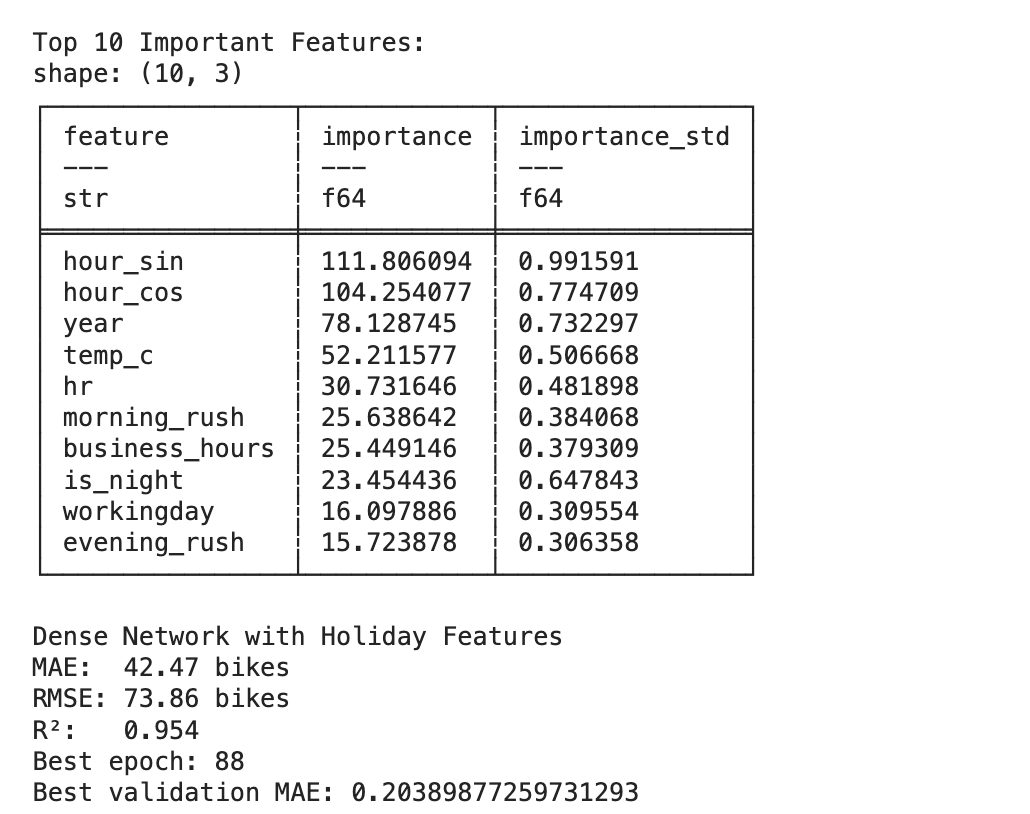

In [25]:
# Sort so the most important feature appears at the top
plot_df = (
    top10_bp2
    .sort("importance")
    .with_columns(
        pl.col("importance")
        .round(2)
        .cast(pl.String)
        .alias("importance_label")
    )
)

x_max = float(
    plot_df["importance"].max()
) * 1.05

feature_order = plot_df["feature"].to_list()

importance_plot = (
    ggplot(
        plot_df,
        aes(
            x="importance",
            y="feature"
        )
    )
    + geom_bar(
        stat="identity",
        fill="#1F77B4",
        width=0.7
    )
    + geom_text(
        aes(label="importance_label"),
        nudge_x=0.01,
        hjust=0,
        size=8,
        color="#333333"
    )
    + scale_y_discrete(
        limits=feature_order
    )
    + scale_x_continuous(
        limits=[0, x_max],
        expand=[0, 0]
    )
    + labs(
        title="Top 10 Features by Feature Importance",
        x="Increase in Validation MAE",
        y="Feature"
    )
    + theme_minimal()
    + theme(
        axis_text_y=element_text(
            margin=[0, 8, 0, 0]
        ),

        axis_text_x=element_text(
            margin=[8, 0, 0, 0]
        ),

        plot_title=element_text(
            size=25,
            face="bold",
            margin=[0, 0, 10, 0]
        ),

        axis_title=element_text(
            size=18,
            face="bold"
        ),

        axis_text=element_text(
            size=14
        ),

        axis_line=element_line(
            color="#444444",
            size=1
        ),

        plot_margin=30,

        panel_grid_major_y=element_blank(),

        panel_grid_major_x=element_line(
            color="#D9D9D9"
        ),

        panel_grid_minor_y=element_blank(),

        panel_grid_minor_x=element_blank(),

        panel_border=element_blank()
    )
    + ggsize(1200, 400)
)

ggsave(importance_plot, "importance_plot.png")

importance_plot

In [ ]:
from sklearn.linear_model import LinearRegression

In [26]:
import itertools
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler


def build_dense_model(
    input_dim,
    learning_rate=0.0005,
    dropout_rate=0.10,
    l2_reg=1e-4,
    activation="relu"
):
    """Creates and compiles the Keras neural network."""
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation=activation, kernel_regularizer=regularizers.l2(l2_reg)),
        layers.Dropout(dropout_rate),
        layers.Dense(64, activation=activation, kernel_regularizer=regularizers.l2(l2_reg)),
        layers.Dropout(dropout_rate / 2.0),
        layers.Dense(32, activation=activation),
        layers.Dense(1)
    ])

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0)
    model.compile(
        optimizer=optimizer,
        loss=keras.losses.Huber(delta=1.0),
        metrics=["mae"]
    )
    return model


def tune_dense_hol(
    data,
    holdout=None,
    test_size=0.2,
    peak_weight=0.75,
    apply_smearing=True
):
    np.random.seed(42)
    tf.random.set_seed(42)

    # 1. Dataset splitting
    if holdout is not None:
        X_train_full = get_X(data)
        y_train_full = get_y(data)
        X_test = get_X(holdout)
        y_test = get_y(holdout) if "total_count" in holdout.columns else None

        y_binned = create_target_bins(y_train_full)
        stratify_opt = y_binned if y_binned is not None else None

        X_train, X_val, y_train, y_val = train_test_split(
            X_train_full,
            y_train_full,
            test_size=0.20,
            random_state=42,
            stratify=stratify_opt
        )
    else:
        X = get_X(data)
        y = get_y(data)

        y_binned = create_target_bins(y)
        stratify_test = y_binned if y_binned is not None else None

        X_train_full, X_test, y_train_full, y_test = train_test_split(
            X,
            y,
            test_size=test_size,
            random_state=42,
            stratify=stratify_test
        )

        y_train_bins = create_target_bins(y_train_full)
        stratify_val = y_train_bins if y_train_bins is not None else None

        X_train, X_val, y_train, y_val = train_test_split(
            X_train_full,
            y_train_full,
            test_size=0.20,
            random_state=42,
            stratify=stratify_val
        )

    # 2. Feature scaling & target transformation
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    y_train_log = np.log1p(y_train)
    y_val_log = np.log1p(y_val)

    # 3. Peak-demand observation weighting
    demand_90th = np.percentile(y_train_log, 90)
    demand_ratio = y_train_log / demand_90th
    sample_weights = 1 + peak_weight * np.clip(demand_ratio, 0, 1)

    # 4. Pure Python / Keras Grid Search (no scikeras required)
    param_grid = {
        "learning_rate": [0.001, 0.0005],
        "dropout_rate": [0.05, 0.10],
        "l2_reg": [1e-4, 1e-3],
        "batch_size": [16, 32]
    }

    # Generate all parameter combinations
    keys, values = zip(*param_grid.items())
    param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

    print(f"Running Grid Search across {len(param_combinations)} combinations (3-fold CV)...")

    kf = KFold(n_splits=3, shuffle=True, random_state=42)
    best_score = float("inf")
    best_params = None

    for i, params in enumerate(param_combinations, 1):
        fold_maes = []

        for train_idx, cv_val_idx in kf.split(X_train):
            cv_X_tr, cv_X_va = X_train[train_idx], X_train[cv_val_idx]
            cv_y_tr, cv_y_va = y_train_log.iloc[train_idx] if hasattr(y_train_log, "iloc") else y_train_log[train_idx], \
                               y_train_log.iloc[cv_val_idx] if hasattr(y_train_log, "iloc") else y_train_log[cv_val_idx]
            cv_sw = sample_weights[train_idx]

            cv_model = build_dense_model(
                input_dim=X_train.shape[1],
                learning_rate=params["learning_rate"],
                dropout_rate=params["dropout_rate"],
                l2_reg=params["l2_reg"]
            )

            cv_model.fit(
                cv_X_tr,
                cv_y_tr,
                sample_weight=cv_sw,
                epochs=15,
                batch_size=params["batch_size"],
                verbose=0
            )

            val_preds = cv_model.predict(cv_X_va, verbose=0).ravel()
            mae = np.mean(np.abs(cv_y_va - val_preds))
            fold_maes.append(mae)

        avg_mae = np.mean(fold_maes)
        print(f"[{i}/{len(param_combinations)}] Params: {params} | Validation MAE: {avg_mae:.4f}")

        if avg_mae < best_score:
            best_score = avg_mae
            best_params = params

    print("\nBest Parameters:", best_params)
    print("Best CV Score (MAE):", best_score)

    # 5. Final Model Retraining with Best Hyperparameters
    final_model = build_dense_model(
        input_dim=X_train.shape[1],
        learning_rate=best_params["learning_rate"],
        dropout_rate=best_params["dropout_rate"],
        l2_reg=best_params["l2_reg"]
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=12,
            min_delta=1e-4,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=1e-6,
            min_delta=1e-4
        )
    ]

    history = final_model.fit(
        X_train,
        y_train_log,
        sample_weight=sample_weights,
        validation_data=(X_val, y_val_log),
        epochs=100,
        batch_size=best_params["batch_size"],
        callbacks=callbacks,
        verbose=1
    )

    # 6. Duan Smearing Factor
    validation_predictions_log = final_model.predict(X_val, verbose=0).ravel()
    if apply_smearing:
        log_residuals = y_val_log - validation_predictions_log
        smearing_factor = np.mean(np.exp(log_residuals))
    else:
        smearing_factor = 1.0

    print("Optimal Smearing Factor:", smearing_factor)

    # 7. Test / Holdout Inference
    predictions_log = final_model.predict(X_test, verbose=0).ravel()
    predictions = (np.exp(predictions_log) * smearing_factor) - 1
    predictions = np.maximum(predictions, 0)

    # 8. Evaluation
    if y_test is not None:
        evaluate_model("Tuned Holiday Dense Network", y_test, predictions)

    return y_test, predictions, history, best_params

In [28]:
# y_test, predictions, history, best_params = tune_dense_hol(data=bike_h)

# MAE Plot

In [29]:
history_input = history_bp2

# 1. Extract loss/MAE metrics from training history
epochs = range(
    1,
    len(history_input.history["mae"]) + 1
)

history_df = pl.DataFrame({
    "epoch": list(epochs),
    "Training MAE": history_input.history["mae"],
    "Validation MAE": history_input.history["val_mae"]
})

# 2. Reshape to long format
plot_history_df = history_df.unpivot(
    index="epoch",
    on=["Training MAE", "Validation MAE"],
    variable_name="Dataset",
    value_name="MAE (log scale)"
)

# 3. Create consistently styled plot
mae_plot = (
    ggplot(
        plot_history_df,
        aes(
            x="epoch",
            y="MAE (log scale)",
            color="Dataset"
        )
    )
    + geom_line(size=1.1)
    + scale_color_manual(
        values={
            "Training MAE": "#2b5c8f",
            "Validation MAE": "#e05a47"
        }
    )
    + ggtitle(
        "Training vs. Validation MAE across Epochs"
    )
    + xlab("Epoch")
    + ylab("MAE (log1p target)")
    + theme_minimal()
    + theme(
        axis_text_y=element_text(
            margin=[0, 8, 0, 0]
        ),

        axis_text_x=element_text(
            margin=[8, 0, 0, 0]
        ),

        plot_title=element_text(
            size=22,
            face="bold",
            margin=[0, 0, 10, 0]
        ),

        axis_title=element_text(
            size=16,
            face="bold"
        ),

        axis_text=element_text(
            size=13
        ),

        axis_line=element_line(
            color="#444444",
            size=1
        ),

        plot_margin=30,

        panel_grid_major=element_line(
            color="#D9D9D9",
            size=0.5
        ),

        panel_grid_minor=element_line(
            color="#D9D9D9",
            size=0.5
        ),

        panel_grid_minor_x=element_blank(),

        legend_position=[1, 0.72],

        legend_justification=[1, 0],

        legend_direction="vertical",

        legend_background=element_rect(
            fill="white",
            color="#999999"
        )
    )
    + ggsize(600, 400)
)

ggsave(mae_plot,"mae_plot.png")

mae_plot

In [30]:
# 1. Slice first 336 hours (14 days) and reshape to long format
ts_df = (
    pl.DataFrame({
        "Hour": np.arange(len(actual_bp2)),
        "Actual": actual_bp2,
        "Predicted": prediction_bp2
    })
    .head(24*7)
    .unpivot(
        index="Hour",
        on=["Actual", "Predicted"],
        variable_name="Series",
        value_name="Bike Count"
    )
)

# 2. Render Time-Series Overlay
p_ts = (
    ggplot(ts_df, aes(x="Hour", y="Bike Count", color="Series"))
    + geom_line(size=1.0, alpha =0.8)
    + scale_color_manual(values={"Actual": "#2b5c8f", "Predicted": "#e05a47"})
    + ggtitle("Hourly Bike Rentals: Actual vs. Predicted (14-Day Window)")
    + xlab("Hour Index")
    + ylab("Total Rental Count")
    + theme_grey()
    + theme(
        legend_position="right",
        panel_grid_major=element_line(color="#e2e6ea", size=0.5)
    )
    +ggsize(1050,420)
)

p_ts.show()

In [32]:
weekly_demand = (
    bike_h
    .with_columns(
        pl.when(pl.col("day_of_week") == 1)
        .then(pl.lit("Monday"))
        .when(pl.col("day_of_week") == 2)
        .then(pl.lit("Tuesday"))
        .when(pl.col("day_of_week") == 3)
        .then(pl.lit("Wednesday"))
        .when(pl.col("day_of_week") == 4)
        .then(pl.lit("Thursday"))
        .when(pl.col("day_of_week") == 5)
        .then(pl.lit("Friday"))
        .when(pl.col("day_of_week") == 6)
        .then(pl.lit("Saturday"))
        .when(pl.col("day_of_week") == 7)
        .then(pl.lit("Sunday"))
        .alias("day_name")
    )
    .with_columns(
        (
            pl.col("hr").cast(pl.Int64)
            +
            (
                (
                    pl.col("day_of_week").cast(pl.Int64) - 1
                ) * 24
            )
        ).alias("week_hour"))
    .group_by([
        "day_name",
        "day_of_week",
        "week_hour"
    ])
    .agg(
        pl.col("total_count")
        .mean()
        .alias("average_count")
    )
    .sort("week_hour")
)

weekday_colors = {
    "Monday": "#E6AB02",
    "Tuesday": "#377eb8",
    "Wednesday": "#4daf4a",
    "Thursday": "#984ea3",
    "Friday": "#ff7f00",
    "Saturday": "#e41a1c",
    "Sunday": "#a65628"
}

weekly_plot = (
    ggplot(
        weekly_demand,
        aes(
            x="week_hour",
            y="average_count",
            color="day_name",
            group="day_name"
        )
    )
    + geom_line(size=1.2)
    + geom_point(size=1.8)
    + scale_color_manual(
        values=weekday_colors
    )
    + scale_x_continuous(
        breaks=[12, 36, 60, 84, 108, 132, 156],
        labels=[
            "Monday",
            "Tuesday",
            "Wednesday",
            "Thursday",
            "Friday",
            "Saturday",
            "Sunday"
        ]
    )
    + labs(
        title="Average Hourly Bike Rental Demand Across a Typical Week",
        x="Day of week",
        y="Average total bike rentals",
        color="Day"
    )
    + theme_minimal()
    + theme(
        axis_text_y=element_text(
            margin=[0, 8, 0, 0]
        ),

        axis_text_x=element_text(
            margin=[8, 0, 0, 0]
        ),

        plot_title=element_text(
            size=22,
            face="bold",
            margin=[0, 0, 10, 0]
        ),

        axis_title=element_text(
            size=16,
            face="bold"
        ),

        axis_text=element_text(
            size=13
        ),

        axis_line=element_line(
            color="#444444",
            size=1
        ),

        plot_margin=30,

        panel_grid_major=element_line(
            color="#D9D9D9"
        ),

        panel_grid_minor=element_line(
            color="#D9D9D9"
        ),

        panel_grid_minor_x=element_blank(),

        legend_position="none"

    )
    + ggsize(900, 300)
)

ggsave(weekly_plot,"weekly_plot.png")
weekly_plot.show()

In [33]:

actual_input = actual_bp2
predictions_input = prediction_bp2

# 1. Build Polars DataFrame
scatter_df = (
    pl.DataFrame({
        "actual": actual_input,
        "predictions": predictions_input
    })
    .with_columns(
        (
            pl.col("actual") -
            pl.col("predictions")
        )
        .abs()
        .alias("abs_diff")
    )
    .with_columns(
        (
            pl.col("abs_diff") /
            pl.max_horizontal(
                pl.col("actual"),
                pl.lit(1.0)
            )
        )
        .alias("pct_diff")
    )
    .with_columns(
        pl.when(pl.col("pct_diff") <= 0.05)
        .then(pl.lit("0–5%"))
        .when(pl.col("pct_diff") <= 0.10)
        .then(pl.lit("5–10%"))
        .when(pl.col("pct_diff") <= 0.20)
        .then(pl.lit("10–20%"))
        .otherwise(pl.lit(">20%"))
        .alias("percent_bucket")
    )
)

bucket_order = [
    "0–5%",
    "5–10%",
    "10–20%",
    ">20%"
]

# 2. Create scatter plot
prediction_plot = (
    ggplot(
        scatter_df,
        aes(
            x="actual",
            y="predictions",
            color="percent_bucket"
        )
    )
    + geom_point(
        alpha=0.65,
        size=2.5
    )
    + geom_abline(
        slope=1,
        intercept=0,
        color="black",
        linetype="dashed",
        size=1.1
    )
    + scale_color_manual(
        breaks=bucket_order,
        values={
            "0–5%": "#1b9e77",
            "5–10%": "#66a61e",
            "10–20%": "#e6ab02",
            ">20%": "#d95f5f"
        }
    )
    + labs(
        title="Actual vs. Predicted Bike Rentals",
        x="Actual Count",
        y="Predicted Count",
        color="Prediction Error"
    )
    + theme_minimal()
    + theme(
        axis_text_y=element_text(
            margin=[0, 8, 0, 0]
        ),

        axis_text_x=element_text(
            margin=[8, 0, 0, 0]
        ),

        plot_title=element_text(
            size=22,
            face="bold",
            margin=[0, 0, 10, 0]
        ),

        axis_title=element_text(
            size=16,
            face="bold"
        ),

        axis_text=element_text(
            size=13
        ),

        axis_line=element_line(
            color="#444444",
            size=1
        ),

        plot_margin=30,

        panel_grid_major=element_line(
            color="#D9D9D9"
        ),

        panel_grid_minor=element_line(
            color="#D9D9D9"
        ),

        panel_grid_minor_x=element_blank(),

        legend_position=[0.25, 0.63],

        legend_justification=[1, 0],

        legend_direction="vertical",

        legend_background=element_rect(
            fill="white",
            color="#999999"
        )
    )
    + ggsize(700, 500)
)

ggsave(
    prediction_plot,
    "prediction_plot.png"
)

prediction_plot

In [74]:
# 3. Calculate the percentage of observations in each error range
error_summary = (
    scatter_df
    .group_by("percent_bucket")
    .agg(
        pl.len().alias("count")
    )
    .with_columns(
        (
            pl.col("count") /
            pl.col("count").sum() *
            100
        ).alias("percentage")
    )
    .with_columns(
        pl.col("percentage")
        .map_elements(
            lambda value: f"{value:.1f}%",
            return_dtype=pl.String
        )
        .alias("percentage_label")
    )
)
max_percentage = float(error_summary["percentage"].max())

# 4. Create percentage bar plot
error_percentage_plot = (
    ggplot(
        error_summary,
        aes(
            x="percent_bucket",
            y="percentage",
            fill="percent_bucket"
        )
    )
    + geom_bar(
        stat="identity",
        width=0.7
    )
    + geom_text(
        aes(label="percentage_label"),
        nudge_y=1.5,
        size=8,
        color="#333333"
    )
    + scale_x_discrete(
        limits=bucket_order
    )
    + scale_y_continuous(
        limits=[0, max_percentage + 5],
        expand=[0, 0]
    )
    + scale_fill_manual(
        breaks=bucket_order,
        values={
            "0–5%": "#1b9e77",
            "5–10%": "#66a61e",
            "10–20%": "#e6ab02",
            ">20%": "#d95f5f"
        }
    )
    + labs(
        title="Percentage of Predictions by Error Range",
        x="Prediction Error",
        y="Percentage of observations"
    )
    + theme_minimal()
    + theme(
        axis_text_y=element_text(
            margin=[0, 8, 0, 0]
        ),
        axis_text_x=element_text(
            margin=[8, 0, 0, 0]
        ),
        plot_title=element_text(
            size=22,
            face="bold",
            margin=[0, 0, 10, 0]
        ),
        axis_title=element_text(
            size=16,
            face="bold"
        ),
        axis_text=element_text(
            size=13
        ),
        axis_line=element_line(
            color="#444444",
            size=1
        ),
        plot_margin=30,
        panel_grid_major=element_line(
            color="#D9D9D9"
        ),
        panel_grid_minor=element_line(
            color="#D9D9D9"
        ),
        panel_grid_minor_x=element_blank(),
        legend_position="none"
    )
    + ggsize(550, 600)
)

ggsave(
    error_percentage_plot,
    "error_percentage_plot.png"
)

error_percentage_plot

In [75]:
# Calculate cumulative percentages
cumulative_df = pl.DataFrame({
    "error_threshold": [
        "Within 5%",
        "Within 10%",
        "Within 20%"
    ],
    "percentage": [
        float((scatter_df["pct_diff"] <= 0.05).mean() * 100),
        float((scatter_df["pct_diff"] <= 0.10).mean() * 100),
        float((scatter_df["pct_diff"] <= 0.20).mean() * 100)
    ],
    "line_group": ["cumulative", "cumulative", "cumulative"]
}).with_columns(
    pl.col("percentage")
    .map_elements(
        lambda value: f"{value:.1f}%",
        return_dtype=pl.String
    )
    .alias("percentage_label")
)

threshold_order = [
    "Within 5%",
    "Within 10%",
    "Within 20%"
]


In [88]:
perc_order=[
            "Within 5%",
            "Within 10%",
            "Within 20%"
        ]
cumulative_percentage_plot = (
    ggplot(
        cumulative_df,
        aes(
            x="error_threshold",
            y="percentage",
            fill='error_threshold'
        )
    )
    + geom_bar(
        stat="identity",
        width=0.65
    )
    + geom_text(
        aes(label="percentage_label"),
        nudge_y=3,
        size=8,
        color="#333333"
    )
    + scale_x_discrete(
        limits=perc_order
    )

    + scale_y_continuous(
        limits=[0, 80],
        breaks=[0, 20, 40, 60, 80]
    )
    + scale_fill_manual(
        breaks=perc_order,
        values={
            "Within 5%": "#1b9e77",
            "Within 10%": "#66a61e",
            "Within 20%": "#e6ab02"
        }
    )
    + labs(
        title="Cumulative Percentage of Predictions",
        x="Prediction Error Threshold",
        y="Cumulative percentage of observations",
        fill = 'Error Threshold'
    )
    + theme_minimal()
    + theme(
        axis_text_y=element_text(
            margin=[0, 8, 0, 0]
        ),
        axis_text_x=element_text(
            margin=[8, 0, 0, 0]
        ),
        plot_title=element_text(
            size=22,
            face="bold",
            margin=[0, 0, 10, 0]
        ),
        axis_title=element_text(
            size=16,
            face="bold"
        ),
        axis_text=element_text(
            size=13
        ),
        axis_line=element_line(
            color="#444444",
            size=1
        ),
        plot_margin=30,
        panel_grid_major=element_line(
            color="#D9D9D9"
        ),
        panel_grid_minor=element_line(
            color="#D9D9D9"
        ),
        panel_grid_minor_x=element_blank(),
        legend_position=[0.33, 0.7],

        legend_justification=[1, 0],

        legend_direction="vertical",

        legend_background=element_rect(
            fill="white",
            color="#999999"
         )
    )
    + ggsize(550, 500)
)

ggsave(
    cumulative_percentage_plot,
    "cumulative_percentage_plot.png"
)

cumulative_percentage_plot

In [34]:

# ---------------------------------------------------------
# Create holiday categories and calculate hourly averages
# ---------------------------------------------------------

hourly_holiday_demand = (
    bike_h
    .with_columns(
        pl.when(pl.col("new_years_day") == 1)
        .then(pl.lit("New Year's Day"))
        .when(pl.col("mlk_day") == 1)
        .then(pl.lit("MLK Day"))
        .when(pl.col("presidents_day") == 1)
        .then(pl.lit("Presidents' Day"))
        .when(pl.col("memorial_day") == 1)
        .then(pl.lit("Memorial Day"))
        .when(pl.col("juneteenth") == 1)
        .then(pl.lit("Juneteenth"))
        .when(pl.col("independence_day") == 1)
        .then(pl.lit("Independence Day"))
        .when(pl.col("labor_day") == 1)
        .then(pl.lit("Labor Day"))
        .when(pl.col("veterans_day") == 1)
        .then(pl.lit("Veterans' Day"))
        .when(pl.col("thanksgiving") == 1)
        .then(pl.lit("Thanksgiving"))
        .when(pl.col("christmas_day") == 1)
        .then(pl.lit("Christmas Day"))
        .otherwise(pl.lit("Normal day"))
        .alias("holiday_name")
    )
    .group_by(["holiday_name", "hr"])
    .agg(
        pl.col("total_count")
        .mean()
        .alias("average_count")
    )
    .sort(["holiday_name", "hr"])
)

# Separate the normal-day baseline from special holidays
normal_day_demand = (
    hourly_holiday_demand
    .filter(
        pl.col("holiday_name") == "Normal day"
    )
)

holiday_demand = (
    hourly_holiday_demand
    .filter(
        pl.col("holiday_name") != "Normal day"
    )
)
# ---------------------------------------------------------
# Color palette
# ---------------------------------------------------------

holiday_colors = {
    "New Year's Day": "#163A5F",
    "MLK Day": "#377EB8",
    "Presidents' Day": "#4DAF4A",
    "Memorial Day": "#984EA3",
    "Juneteenth": "#FF7F00",
    "Independence Day": "#A65628",
    "Labor Day": "#F781BF",
    "Veterans' Day": "#999999",
    "Thanksgiving": "#66C2A5",
    "Christmas Day": "#E6AB02",
    "Normal day": "#E41A1C"
}

holiday_plot=(
    # ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

ggplot() + \

    # Special holiday profiles
    geom_line(
        data=holiday_demand.to_dict(as_series=False),
        mapping=aes(
            x="hr",
            y="average_count",
            color="holiday_name",
            group="holiday_name"
        ),
        size=0.9,
        alpha=0.65
    ) + \

    geom_point(
        data=holiday_demand.to_dict(as_series=False),
        mapping=aes(
            x="hr",
            y="average_count",
            color="holiday_name",
            group="holiday_name"
        ),
        size=1.2,
        alpha=0.65
    ) + \

    # Bold normal-day baseline
    geom_line(
        data=normal_day_demand.to_dict(as_series=False),
        mapping=aes(
            x="hr",
            y="average_count",
            color="holiday_name",
            group="holiday_name"
        ),
        size=2.5
    ) + \

    geom_point(
        data=normal_day_demand.to_dict(as_series=False),
        mapping=aes(
            x="hr",
            y="average_count",
            color="holiday_name",
            group="holiday_name"
        ),
        size=2.5
    ) + \

    scale_color_manual(
        values=holiday_colors
    ) + \

    scale_x_continuous(
        breaks=list(range(0, 23, 2))
    ) + \

    labs(
        title="Hourly Bike Demand on Holidays Compared with a Normal Day",
        subtitle="The red line represents the typical hourly rental pattern on non-holidays",
        x="Hour of day",
        y="Average total bike rentals",
        color="Day type"
    ) + \

    theme_minimal() + \

    theme(
        axis_text_y=element_text(
            margin=[0, 8, 0, 0]
        ),

        axis_text_x=element_text(
            margin=[8, 0, 0, 0]
        ),

        plot_title=element_text(
            size=22,
            face="bold",
            margin=[0, 0, 10, 0]
        ),

        plot_subtitle=element_text(
            size=13,
            color="#555555",
            margin=[0, 0, 12, 0]
        ),

        axis_title=element_text(
            size=16,
            face="bold"
        ),

        axis_text=element_text(
            size=13
        ),

        axis_line=element_line(
            color="#444444",
            size=1
        ),

        plot_margin=30,

        panel_grid_major=element_line(
            color="#D9D9D9"
        ),

        panel_grid_minor=element_line(
            color="#D9D9D9"
        ),

        panel_grid_minor_x=element_blank(),

        legend_position=[0.22, 0.16],

        legend_justification=[1, 0],

        legend_direction="vertical",

        legend_background=element_rect(
            fill="white",
            color="#999999"
        )
    ) + \

    ggsize(900, 500)
)

ggsave(holiday_plot,"holiday_plot.png")
holiday_plot


In [57]:
hourly_season_demand = (
    bike_h
    .with_columns(
        pl.when(pl.col("season") == 1)
        .then(pl.lit("Spring"))
        .when(pl.col("season") == 2)
        .then(pl.lit("Summer"))
        .when(pl.col("season") == 3)
        .then(pl.lit("Fall"))
        .when(pl.col("season") == 4)
        .then(pl.lit("Winter"))
        .otherwise(pl.lit("Unknown"))
        .alias("season_name")
    )
    .group_by(["season_name", "hr"])
    .agg(
        pl.col("total_count")
        .mean()
        .alias("average_count")
    )
    .sort(["season_name", "hr"])
)
season_colors = {
    "Spring": "#1b9e77",
    "Summer": "#e6ab02",
    "Fall": "#d95f02",
    "Winter": "#7570b3",
}

season_plot = (
    ggplot(
        hourly_season_demand.to_dict(as_series=False),
        aes(
            x="hr",
            y="average_count",
            color="season_name",
            group="season_name"
        )
    )
    + geom_line(size=1.2)
    + geom_point(size=2)
    + scale_color_manual(
        values=season_colors
    )
    + labs(
        title="Average Hourly Bike Demand by Season",
        x="Hour of day",
        y="Average total bike rentals",
        color="Season"
    )
    + theme_minimal()
    + theme(
        axis_text_y=element_text(
            margin=[0, 8, 0, 0]
        ),
        axis_text_x=element_text(
            margin=[8, 0, 0, 0]
        ),
        plot_title=element_text(
            size=22,
            face="bold",
            margin=[0, 0, 10, 0]
        ),
        axis_title=element_text(
            size=16,
            face="bold"
        ),
        axis_text=element_text(
            size=13
        ),
        axis_line=element_line(
            color="#444444",
            size=1
        ),
        plot_margin=30,
        panel_grid_major=element_line(
            color="#D9D9D9"
        ),
        panel_grid_minor=element_line(
            color="#D9D9D9"
        ),
        panel_grid_minor_x=element_blank(),
        legend_position=[0.22, 0.46],

        legend_justification=[1, 0],

        legend_direction="vertical",

        legend_background=element_rect(
            fill="white",
            color="#999999"
        )
    )
)

season_plot.show()

In [59]:
hourly_weekend_demand = (
    bike_h
    .with_columns(
        pl.when(pl.col("is_weekend") == 1)
        .then(pl.lit("Weekend"))
        .otherwise(pl.lit("Weekday"))
        .alias("day_type")
    )
    .group_by(["day_type", "hr"])
    .agg(
        pl.col("total_count")
        .mean()
        .alias("average_count")
    )
    .sort(["day_type", "hr"])
)

day_type_colors = {
    "Weekday": "#2b5c8f",
    "Weekend": "#e05a47"
}

weekday_weekend_plot = (
    ggplot(
        hourly_weekend_demand.to_dict(as_series=False),
        aes(
            x="hr",
            y="average_count",
            color="day_type",
            group="day_type"
        )
    )
    + geom_line(size=1.2)
    + geom_point(size=2)
    + scale_color_manual(
        values=day_type_colors
    )
    + labs(
        title="Average Hourly Bike Demand by Day Type",
        x="Hour of day",
        y="Average total bike rentals",
        color="Day type"
    )
    + theme_minimal()
    + theme(
        axis_text_y=element_text(
            margin=[0, 8, 0, 0]
        ),
        axis_text_x=element_text(
            margin=[8, 0, 0, 0]
        ),
        plot_title=element_text(
            size=22,
            face="bold",
            margin=[0, 0, 10, 0]
        ),
        axis_title=element_text(
            size=16,
            face="bold"
        ),
        axis_text=element_text(
            size=13
        ),
        axis_line=element_line(
            color="#444444",
            size=1
        ),
        plot_margin=30,
        panel_grid_major=element_line(
            color="#D9D9D9"
        ),
        panel_grid_minor=element_line(
            color="#D9D9D9"
        ),
        panel_grid_minor_x=element_blank(),
        legend_position=[0.22, 0.65],

        legend_justification=[1, 0],

        legend_direction="vertical",

        legend_background=element_rect(
            fill="white",
            color="#999999"
        )
    )
)

combined_plot = (
    gggrid(
        plots=[
            season_plot,
            weekday_weekend_plot
        ],
        ncol=2
    )
    + ggsize(1200, 400)
)

ggsave(combined_plot,"combined_plot.png")

combined_plot.show()


# Mini Holdout

In [ ]:
mini_raw=pl.read_csv("https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/biking_holdout_test_mini.csv")

In [ ]:
mini_h=cleanh(mini_raw, test= True)
mini_h.describe()

statistic,dteday,hr,temp_c,feels_like_c,hum,windspeed,weathersit,season,holiday,workingday,date,year,month,day_of_month,day_of_year,day_of_week,is_weekend,morning_rush,evening_rush,is_night,business_hours,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos,year_sin,year_cos,is_holiday,day_after_holiday,day_before_holiday,holiday_weekend,new_years_day,mlk_day,presidents_day,memorial_day,juneteenth,independence_day,labor_day,veterans_day,thanksgiving,christmas_day
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""384""",384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,"""384""",384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0,384.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",null,11.5,7.973958,6.471875,0.595443,12.374479,1.263021,4.0,0.0625,0.6875,"""2023-11-22 12:00:00""",2023.0,11.0,22.5,326.5,3.9375,0.25,0.125,0.166667,0.333333,0.416667,0.0,-1.1102e-16,0.0,-0.112621,-0.5,0.866025,-0.61637,0.783463,0.0625,0.0625,0.0625,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0625,0.0
"""std""",null,6.931217,4.987274,6.196933,0.180419,7.669153,0.596847,0.0,0.242377,0.464117,null,0.0,0.0,4.615786,4.615786,1.888885,0.433578,0.33115,0.373164,0.47202,0.49365,0.708029,0.708029,0.679879,0.726401,0.0,1.5721e-16,0.062312,0.049053,0.242377,0.242377,0.242377,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.242377,0.0
"""min""","""11/15/2023""",0.0,-3.8,-7.6,0.2515,0.0,1.0,4.0,0.0,0.0,"""2023-11-15""",2023.0,11.0,15.0,319.0,1.0,0.0,0.0,0.0,0.0,0.0,-1.0,-1.0,-0.974928,-0.900969,-0.5,0.866025,-0.714292,0.699848,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",null,6.0,4.5,2.4,0.4557,6.9,1.0,4.0,0.0,0.0,"""2023-11-19""",2023.0,11.0,19.0,323.0,3.0,0.0,0.0,0.0,0.0,0.0,-0.707107,-0.707107,-0.433884,-0.900969,-0.5,0.866025,-0.664483,0.747303,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""50%""",null,12.0,7.8,6.1,0.5651,11.4,1.0,4.0,0.0,1.0,"""2023-11-23""",2023.0,11.0,23.0,327.0,4.0,0.0,0.0,0.0,0.0,0.0,1.2246e-16,6.1232e-17,-2.4493e-16,-0.222521,-0.5,0.866025,-0.61153,0.791221,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""75%""",null,17.0,11.5,11.5,0.7196,16.8,1.0,4.0,0.0,1.0,"""2023-11-26""",2023.0,11.0,26.0,330.0,5.0,0.0,0.0,0.0,1.0,1.0,0.707107,0.707107,0.433884,0.62349,-0.5,0.866025,-0.569901,0.821713,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""max""","""11/30/2023""",23.0,21.2,21.2,0.9688,39.3,3.0,4.0,1.0,1.0,"""2023-11-30""",2023.0,11.0,30.0,334.0,7.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.974928,1.0,-0.5,0.866025,-0.512055,0.858953,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:

actual, predictions,his=dense_hol(bike_h,mini_h)

results_df = pl.DataFrame({
    "price": predictions
})
results_df.write_csv("team2bp-module4-predictions.csv")

Epoch 1/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 0.3787 - mae: 0.5459 - val_loss: 0.1199 - val_mae: 0.3533 - learning_rate: 0.0010
Epoch 2/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.1814 - mae: 0.3700 - val_loss: 0.0997 - val_mae: 0.3114 - learning_rate: 0.0010
Epoch 3/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.1533 - mae: 0.3342 - val_loss: 0.0907 - val_mae: 0.2930 - learning_rate: 0.0010
Epoch 4/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.1403 - mae: 0.3163 - val_loss: 0.0888 - val_mae: 0.2859 - learning_rate: 0.0010
Epoch 5/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.1254 - mae: 0.2959 - val_loss: 0.0834 - val_mae: 0.2759 - learning_rate: 0.0010
Epoch 6/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.1125 - mae: 0.2773 - val_loss: 0.0729 - val_mae: 0.2521 - learning_rate: 0.0010
Epoch 7/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 0.1054 - mae: 0.2666 - val_loss: 0.0721 - val_mae: 0.2495 - learn

# Real Holdout


In [ ]:
real_raw=pl.read_csv("https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes_december.csv")

In [ ]:
real_h=cleanh(real_raw, test= True)

In [ ]:
actual, predictions,his=dense_hol(bike_h,real_h)

results_df = pl.DataFrame({
    "price": predictions
})
results_df.write_csv("team2real-module4-predictions.csv")

Epoch 1/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 0.3398 - mae: 0.5196 - val_loss: 0.1148 - val_mae: 0.3436 - learning_rate: 0.0010
Epoch 2/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.1717 - mae: 0.3567 - val_loss: 0.0956 - val_mae: 0.3025 - learning_rate: 0.0010
Epoch 3/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.1433 - mae: 0.3211 - val_loss: 0.0871 - val_mae: 0.2832 - learning_rate: 0.0010
Epoch 4/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.1278 - mae: 0.2994 - val_loss: 0.0825 - val_mae: 0.2727 - learning_rate: 0.0010
Epoch 5/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - loss: 0.1185 - mae: 0.2864 - val_loss: 0.0775 - val_mae: 0.2618 - learning_rate: 0.0010
Epoch 6/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.1131 - mae: 0.2786 - val_loss: 0.0747 - val_mae: 0.2595 - learning_rate: 0.0010
Epoch 7/100
2812/2812 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.1088 - mae: 0.2719 - val_loss: 0.0714 - val_mae: 0.2513 - learni

In [1]:
from sklearn.metrics import mean_absolute_error
import polars as pl
import numpy as np

def permutation_importance_nn(
    model,
    X_val,
    y_val_log,
    feature_names,
    n_repeats=10
):
    y_val = np.expm1(y_val_log)

    # Baseline prediction error
    base_predictions_log = model.predict(
        X_val,
        verbose=0
    ).ravel()

    base_predictions = np.maximum(
        np.expm1(base_predictions_log),
        0
    )

    base_mae = mean_absolute_error(
        y_val,
        base_predictions
    )

    rng = np.random.default_rng(42)
    results = []

    for feature_index, feature_name in enumerate(feature_names):

        shuffled_mae = []

        for _ in range(n_repeats):

            X_permuted = X_val.copy()

            shuffled_values = X_permuted[:, feature_index].copy()
            rng.shuffle(shuffled_values)

            X_permuted[:, feature_index] = shuffled_values

            predictions_log = model.predict(
                X_permuted,
                verbose=0
            ).ravel()

            predictions = np.maximum(
                np.expm1(predictions_log),
                0
            )

            permuted_mae = mean_absolute_error(
                y_val,
                predictions
            )

            shuffled_mae.append(permuted_mae)

        results.append({
            "feature": feature_name,
            "importance": np.mean(shuffled_mae) - base_mae,
            "importance_std": np.std(shuffled_mae)
        })

    return (
        pl.DataFrame(results)
        .sort("importance", descending=True)
    )
